# 06a · What an embedding sees

**Week 10, segment 10.6.** We embed about 120 sentences with the same model the retrieval demo uses, and look at the space it puts them in.

Six steps: **(1)** embed, **(2)** the cosine matrix, **(3)** a 2-D map (UMAP), **(4)** planted pairs that show what vectors capture and what they lose, **(5)** drop your own sentence on the map, **(6)** why the map is a picture and the cosine is the measurement. A small word-level panel sits at the end.

Run from `part4_code_v2` after `uv sync --extra notebook`:

```
uv run --extra notebook jupyter lab week10/06a_embedding_map.ipynb
```

In [1]:
import sys, pathlib, warnings
warnings.filterwarnings("ignore")
ROOT = pathlib.Path.cwd() if (pathlib.Path.cwd() / "common").is_dir() else pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots
import plotly.io as pio
import umap
from sklearn.decomposition import PCA
from common import retrieval

pio.templates.default = "plotly_white"
FONT = dict(family="Helvetica, Arial, sans-serif", size=16)

def embed(texts):
    "Real embeddings only. The hashed fallback has no semantics, and a map of it would be noise."
    texts = list(texts)
    try:
        v = retrieval._embed_st(texts); backend = "sentence-transformers / " + (retrieval.EMBED_MODEL or "all-MiniLM-L6-v2")
    except ImportError:
        try:
            v = retrieval._embed_ollama(texts); backend = "ollama / " + (retrieval.EMBED_MODEL or "nomic-embed-text")
        except Exception as e:
            raise RuntimeError("No real embedding model. Run `uv sync --extra notebook`, "
                               "or `ollama pull nomic-embed-text`.") from e
    embed.backend = backend
    return np.asarray(v, dtype=float)

print("ready")

ready


## 1 · Embed

Six topics. The first three (physics, cell biology, machine learning) are neighbours on purpose: science sentences share vocabulary, so their regions should touch. The last three are far from them and from each other. A seventh group, **probes**, holds the planted pairs for step 4.

In [4]:
TOPICS = {
 "particle & nuclear physics": [
  "The Higgs boson was discovered at the Large Hadron Collider in 2012.",
  "Neutrinos oscillate between three flavours as they travel.",
  "Beta decay turns a neutron into a proton, an electron and an antineutrino.",
  "The half-life of cobalt-60 is about 5.27 years.",
  "Quarks are confined inside protons and neutrons by the strong force.",
  "A germanium detector measures gamma-ray energies with high resolution.",
  "The Standard Model does not explain dark matter.",
  "Muons decay into electrons and two neutrinos.",
  "Electron capture competes with positron emission in proton-rich nuclei.",
  "The proton radius was measured with muonic hydrogen.",
  "Cosmic rays produce showers of particles in the upper atmosphere.",
  "A cyclotron accelerates charged particles along a spiral path.",
  "Parity is violated in the weak interaction.",
  "Scintillators emit light when ionizing radiation passes through them.",
  "The binding energy per nucleon peaks near iron.",
  "Antimatter annihilates with matter and produces photons.",
  "Cross sections are measured in barns.",
  "A trigger system decides which collisions are recorded.",
 ],
 "cell biology": [
  "Mitochondria produce most of the cell's ATP.",
  "DNA is wrapped around histone proteins to form nucleosomes.",
  "Ribosomes translate messenger RNA into protein.",
  "Stem cells can differentiate into many cell types.",
  "Histone acetylation is associated with active transcription.",
  "The cell membrane is a lipid bilayer with embedded proteins.",
  "Tumour cells often carry mutations in the p53 gene.",
  "Mass cytometry measures dozens of proteins in single cells.",
  "During mitosis the chromosomes are pulled to opposite poles.",
  "Enzymes lower the activation energy of biochemical reactions.",
  "T cells recognise antigens presented on the surface of other cells.",
  "CRISPR uses a guide RNA to cut DNA at a chosen site.",
  "Apoptosis is programmed cell death.",
  "Methylation of DNA can silence a gene without changing its sequence.",
  "Antibodies bind specific epitopes on their targets.",
  "The cytoskeleton gives the cell its shape and moves cargo.",
  "Bacteria divide by binary fission.",
  "Single-cell sequencing reveals heterogeneity inside a tumour.",
 ],
 "machine learning": [
  "A transformer uses self-attention instead of recurrence.",
  "Gradient descent updates the weights to reduce the loss.",
  "Overfitting means the model memorised the training set.",
  "Dropout randomly disables neurons during training.",
  "A language model predicts the next token.",
  "Embeddings map text to vectors in a high-dimensional space.",
  "Retrieval-augmented generation puts documents into the prompt.",
  "The learning rate controls the size of each update step.",
  "Convolutional networks are good at recognising images.",
  "Reinforcement learning optimises a reward signal.",
  "Quantization stores each weight with fewer bits.",
  "An agent calls tools in a loop until it has an answer.",
  "Batch normalisation stabilises the training of deep networks.",
  "The validation set is used to choose hyperparameters.",
  "Attention weights say which tokens influence which.",
  "Fine-tuning adapts a pretrained model to a new task.",
  "A variational autoencoder learns a latent distribution.",
  "Backpropagation computes gradients with the chain rule.",
 ],
 "cooking": [
  "Simmer the tomato sauce for twenty minutes.",
  "Knead the dough until it is smooth and elastic.",
  "Add a pinch of salt to the boiling water before the pasta.",
  "Roast the vegetables at 200 degrees until golden.",
  "Whisk the eggs with sugar until pale and fluffy.",
  "Let the steak rest for five minutes before slicing.",
  "Fresh basil goes on the pizza after it comes out of the oven.",
  "Toast the spices in a dry pan to release their aroma.",
  "The bread needs to rise for an hour in a warm place.",
  "Caramelise the onions slowly over low heat.",
  "Fold the chocolate into the batter gently.",
  "Hummus is made from chickpeas, tahini, lemon and garlic.",
  "Marinate the chicken overnight in yoghurt and spices.",
  "A sharp knife is safer than a dull one in the kitchen.",
  "Deglaze the pan with a splash of white wine.",
  "Sourdough starter is fed with flour and water every day.",
  "Grate fresh parmesan over the risotto just before serving.",
  "Shakshuka is eggs poached in a spiced tomato sauce.",
 ],
 "sport": [
  "The striker scored twice in the second half.",
  "She won the marathon in two hours and nineteen minutes.",
  "The goalkeeper saved a penalty in extra time.",
  "The team was relegated after losing its last five matches.",
  "He served an ace to win the tennis final.",
  "The cyclists climbed the mountain pass in the rain.",
  "A three-pointer at the buzzer decided the basketball game.",
  "The referee showed a red card for a dangerous tackle.",
  "The swimmer broke the world record in the 100 metre freestyle.",
  "The coach changed tactics at half-time.",
  "The sprinter was disqualified for a false start.",
  "The home crowd cheered as the team lifted the trophy.",
  "She trains six days a week for the Olympic Games.",
  "The match ended in a goalless draw.",
  "The quarterback threw a long pass for a touchdown.",
  "The gymnast landed a perfect vault.",
  "The club signed a new midfielder in the transfer window.",
  "The rowing crew crossed the finish line half a length ahead.",
 ],
 "weather & travel": [
  "It will rain heavily in the north tomorrow afternoon.",
  "The flight to Rome was delayed by three hours.",
  "A heat wave is expected to last until the weekend.",
  "The train leaves from platform four at nine o'clock.",
  "Snow closed the mountain road for two days.",
  "We booked a small hotel near the old harbour.",
  "Strong winds are forecast along the coast tonight.",
  "My suitcase was lost somewhere between two airports.",
  "The morning fog lifted and the sun came out.",
  "You need a visa to enter the country as a tourist.",
  "The humidity makes the summer nights uncomfortable.",
  "The ferry to the island runs twice a day.",
  "A thunderstorm knocked out the power in the village.",
  "We rented a car and drove along the coast.",
  "Temperatures will drop below freezing overnight.",
  "The museum is a ten-minute walk from the station.",
  "Pack a raincoat, the forecast looks unsettled.",
  "The airport bus stops in front of the central station.",
 ],
}

# Planted pairs for step 4. (label, sentence a, sentence b)
PROBES = [
 ("paraphrase, no shared words", "How accurate is AlphaFold?", "The median backbone error of the predicted protein structures was 0.96 angstrom."),
 ("paraphrase, everyday",        "The plane was late.", "Our flight got delayed."),
 ("negation",                    "The drug inhibits the enzyme.", "The drug does not inhibit the enzyme."),
 ("numbers",                     "The method improved accuracy by 17.9 points.", "The method improved accuracy by 19.7 points."),
 ("opposite meaning",            "The treatment increased tumour growth.", "The treatment decreased tumour growth."),
 ("same word, other meaning",    "The cell divided into two daughter cells.", "He spent the night in a prison cell."),
 ("same word, other meaning 2",  "The battery cell stores charge.", "The cell divided into two daughter cells."),
 ("unrelated (control)",         "Quarks are held together by gluons.", "Whisk the cream until it forms soft peaks."),
]

sentences, labels = [], []
for topic, ss in TOPICS.items():
    sentences += ss; labels += [topic] * len(ss)
probe_sents = list(dict.fromkeys(s for _, a, b in PROBES for s in (a, b)))
sentences += probe_sents; labels += ["probes"] * len(probe_sents)
labels = np.array(labels)

E = embed(sentences)
print("matrix:", E.shape, "  (sentences x dimensions), every row has length", round(float(np.linalg.norm(E[0])), 3))
print()
print(repr(sentences[0]))
print("->", np.round(E[0][:12], 3), "... and", E.shape[1] - 12, "more numbers")

matrix: (123, 768)   (sentences x dimensions), every row has length 1.0

'The Higgs boson was discovered at the Large Hadron Collider in 2012.'
-> [ 0.033  0.075 -0.166 -0.07   0.04   0.035 -0.016  0.084 -0.014 -0.053
 -0.062  0.025] ... and 756 more numbers


## 2 · The cosine matrix: the honest picture

Every row has length 1, so `E @ E.T` is the cosine between every pair of sentences. Nothing is projected or thrown away here. Sentences are ordered by topic, so a topic shows up as a bright square on the diagonal. Look for the faint glow **between** the three science blocks, and for the dark cross where cooking meets physics.

## 3 · The map

384 dimensions cannot be drawn, so we project to two with **UMAP** (Uniform Manifold Approximation and Projection): it tries to keep each sentence next to its nearest neighbours in the original space. Hover over a point to read the sentence. Nobody told the model the topics; the colours were added afterwards.

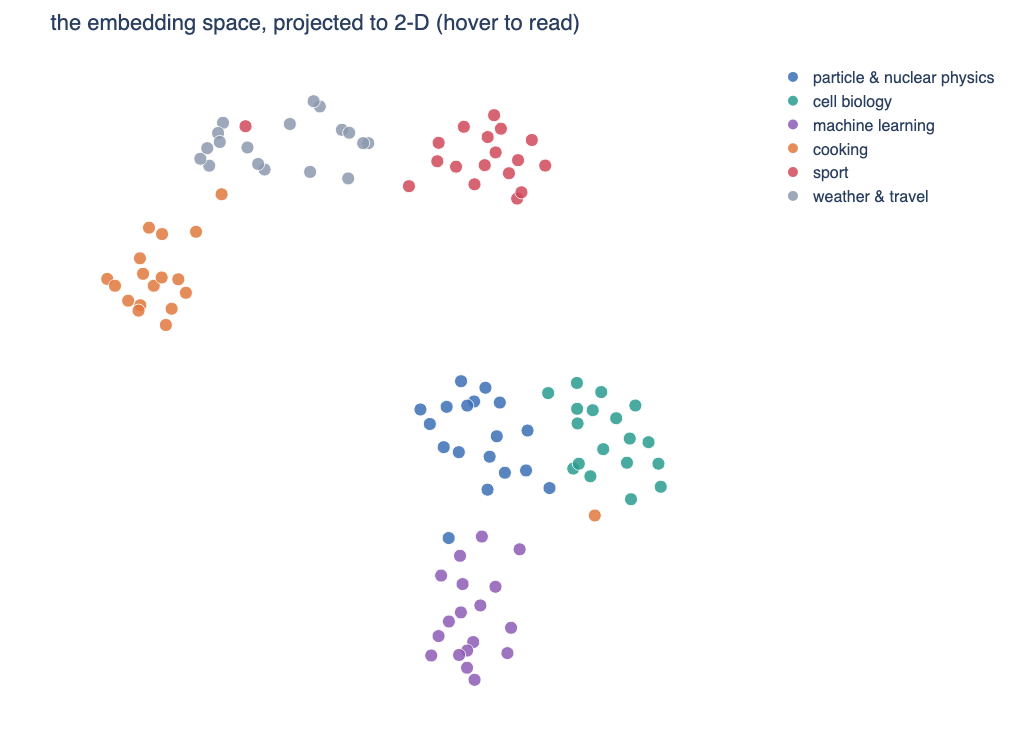

In [5]:
PALETTE = {"particle & nuclear physics": "#3B6FB6", "cell biology": "#2A9D8F", "machine learning": "#8E5BB5",
           "cooking": "#E07A3F", "sport": "#D1495B", "weather & travel": "#8D99AE", "probes": "#111111"}

reducer = umap.UMAP(n_neighbors=12, min_dist=0.35, metric="cosine", random_state=7)
XY = reducer.fit_transform(E)

def wrap(s, n=48):
    out, line = [], ""
    for w in s.split():
        if len(line) + len(w) > n: out.append(line); line = ""
        line += w + " "
    return "<br>".join(out + [line.strip()])

def base_map(title, show_probes=True):
    fig = go.Figure()
    for t, col in PALETTE.items():
        if t == "probes" and not show_probes: continue
        m = labels == t
        fig.add_trace(go.Scatter(x=XY[m, 0], y=XY[m, 1], mode="markers", name=t,
                                 marker=dict(size=13 if t != "probes" else 11, color=col, opacity=0.85,
                                             symbol="circle" if t != "probes" else "diamond", line=dict(color="white", width=1)),
                                 text=[wrap(s) for s in np.array(sentences)[m]], hovertemplate="%{text}<extra>" + t + "</extra>"))
    fig.update_layout(width=1050, height=720, font=FONT, title=title, legend=dict(itemsizing="constant"),
                      xaxis=dict(visible=False), yaxis=dict(visible=False, scaleanchor="x"),
                      hoverlabel=dict(font_size=15), margin=dict(l=10, r=10, t=60, b=10))
    return fig

base_map("the embedding space, projected to 2-D (hover to read)", show_probes=False).show()

## 4 · Planted pairs: what the vector captures, and what it loses

Each pair below is drawn as a line on the map, with its cosine. Read the cosine column before the picture.

- **Paraphrases** with almost no shared words are close. This is the reason to use embeddings at all.
- **Negation**, **swapped numbers** and **opposite meanings** are also close, often closer than the paraphrases. To the embedder these are "the same sentence". For retrieval that is a hazard; it is why the next slides add BM25.
- **The same word in another meaning** is pulled apart by context.

pair                           cosine
numbers                         0.98  #######################################
                                      The method improved accuracy by 17.9 points.
                                      The method improved accuracy by 19.7 points.
opposite meaning                0.94  #####################################
                                      The treatment increased tumour growth.
                                      The treatment decreased tumour growth.
negation                        0.94  #####################################
                                      The drug inhibits the enzyme.
                                      The drug does not inhibit the enzyme.
paraphrase, everyday            0.76  ##############################
                                      The plane was late.
                                      Our flight got delayed.
same word, other meaning 2      0.56  ######################
                  

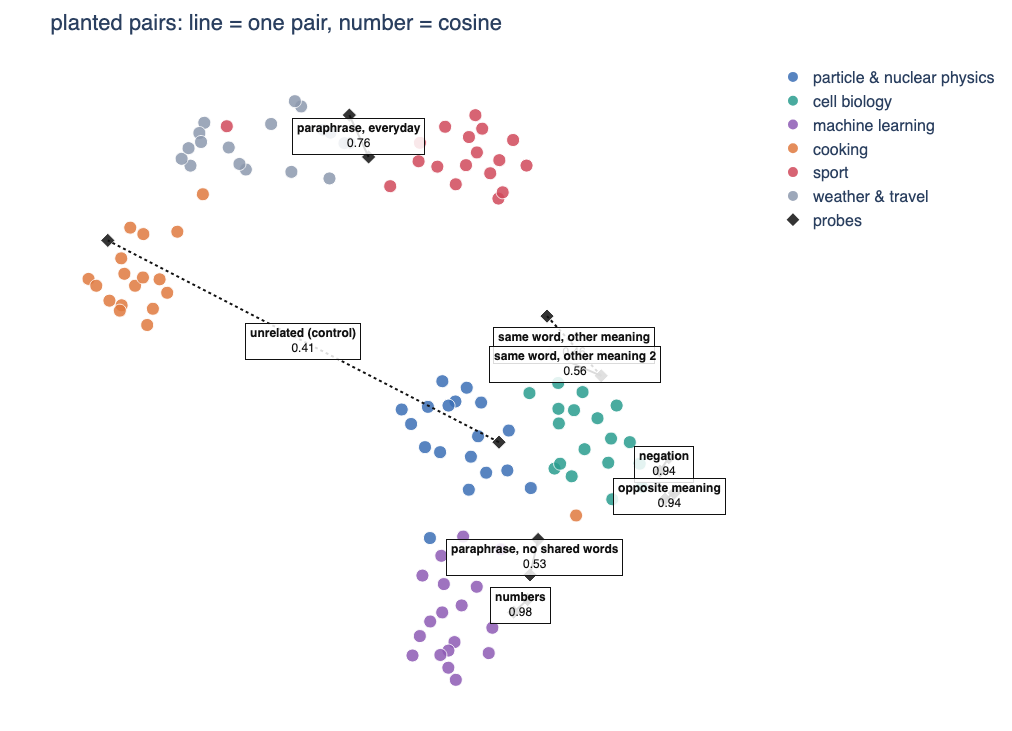

In [6]:
idx = {s: i for i, s in enumerate(sentences)}
rows = []
for label, a, b in PROBES:
    rows.append((label, float(E[idx[a]] @ E[idx[b]]), a, b))
print(f"{'pair':30s} cosine")
for label, c, a, b in sorted(rows, key=lambda r: -r[1]):
    bar = "#" * int(max(c, 0) * 40)
    print(f"{label:30s} {c:5.2f}  {bar}\n{'':30s}        {a}\n{'':30s}        {b}")

fig = base_map("planted pairs: line = one pair, number = cosine")
for label, c, a, b in rows:
    i, j = idx[a], idx[b]
    fig.add_trace(go.Scatter(x=[XY[i, 0], XY[j, 0]], y=[XY[i, 1], XY[j, 1]], mode="lines",
                             line=dict(color="#111111", width=2, dash="solid" if c > 0.5 else "dot"),
                             hoverinfo="skip", showlegend=False))
    fig.add_annotation(x=(XY[i, 0] + XY[j, 0]) / 2, y=(XY[i, 1] + XY[j, 1]) / 2, text=f"<b>{label}</b><br>{c:.2f}",
                       showarrow=False, font=dict(size=12, color="#111111"), bgcolor="rgba(255,255,255,0.85)", bordercolor="#111111", borderpad=3)
fig.show()

## 5 · Your sentence on the map

This is retrieval, made visible: embed a query with the **same** model, find its nearest neighbours by cosine, and that is the top-k. Type a sentence and press Enter. The star is where it lands; the lines go to its five nearest neighbours **measured in the 384-dimensional space**, which is why a line sometimes reaches further across the picture than you expect.

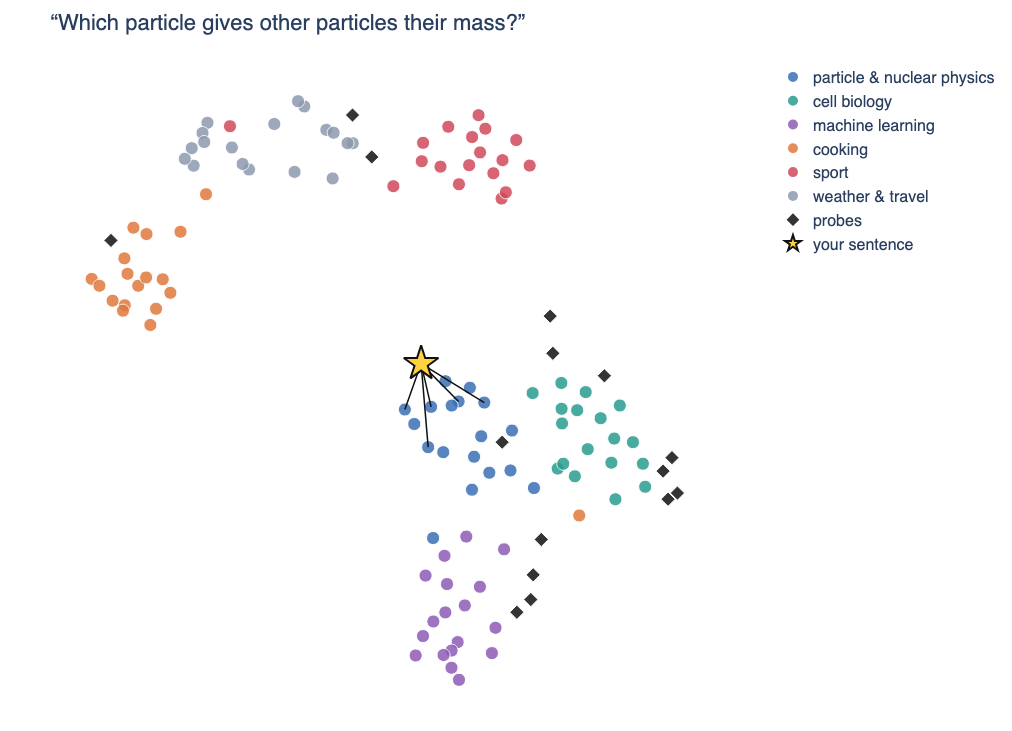

nearest neighbours of: 'Which particle gives other particles their mass?'
  0.61  [particle & nuclear physics]  A cyclotron accelerates charged particles along a spiral path.
  0.58  [particle & nuclear physics]  Antimatter annihilates with matter and produces photons.
  0.58  [particle & nuclear physics]  Cosmic rays produce showers of particles in the upper atmosphere.
  0.57  [particle & nuclear physics]  Beta decay turns a neutron into a proton, an electron and an antineutrino.
  0.57  [particle & nuclear physics]  Electron capture competes with positron emission in proton-rich nuclei.


In [7]:
def place(query, k=5):
    q = embed([query])[0]
    sims = E @ q
    top = np.argsort(-sims)[:k]
    xy = reducer.transform(q[None, :])[0]
    fig = base_map(f"“{query}”")
    for i in top:
        fig.add_trace(go.Scatter(x=[xy[0], XY[i, 0]], y=[xy[1], XY[i, 1]], mode="lines", line=dict(color="#111111", width=1.5),
                                 hoverinfo="skip", showlegend=False))
    fig.add_trace(go.Scatter(x=[xy[0]], y=[xy[1]], mode="markers", name="your sentence",
                             marker=dict(size=26, symbol="star", color="#FFD23F", line=dict(color="#111111", width=2)),
                             text=[wrap(query)], hovertemplate="%{text}<extra>query</extra>"))
    fig.show()
    print(f"nearest neighbours of: {query!r}")
    for i in top:
        print(f"  {sims[i]:.2f}  [{labels[i]}]  {sentences[i]}")

place("Which particle gives other particles their mass?")

In [8]:
# Live box: type a sentence, press Enter. (If the widget does not render, call place("...") in a cell.)
import ipywidgets as W
from IPython.display import display, clear_output
box = W.Text(placeholder="type a sentence and press Enter", layout=W.Layout(width="760px"))
out = W.Output()
def _go(_):
    with out:
        clear_output(wait=True); place(box.value.strip())
box.continuous_update = False          # fire on Enter (or when the box loses focus)
box.observe(lambda change: _go(change) if change["new"].strip() else None, names="value")
display(box, out)

Text(value='', continuous_update=False, layout=Layout(width='760px'), placeholder='type a sentence and press E…

Output()

## 6 · The map is a picture; the cosine is the measurement

Three projections of the **same** 384-dimensional vectors: UMAP with two different random seeds, and PCA (principal component analysis, a linear projection). The groups survive in all three. Their positions, the distances between groups, and the shapes do not. So: read a map for *who is near whom*, never for *how far*. Retrieval never looks at the map. It uses the cosine.

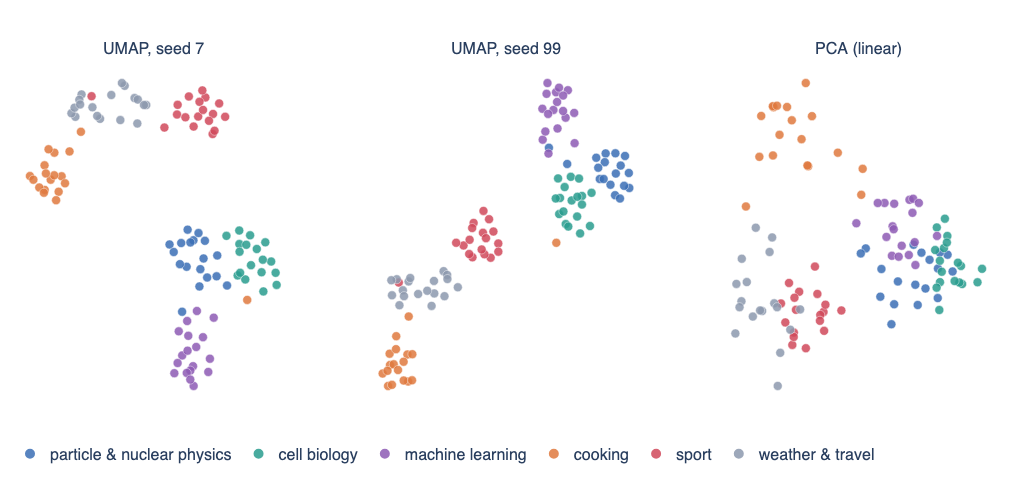

UMAP, seed 7   keeps 62% of each sentence's 10 true nearest neighbours
UMAP, seed 99  keeps 63% of each sentence's 10 true nearest neighbours
PCA (linear)   keeps 37% of each sentence's 10 true nearest neighbours


In [9]:
proj = {"UMAP, seed 7": XY,
        "UMAP, seed 99": umap.UMAP(n_neighbors=12, min_dist=0.35, metric="cosine", random_state=99).fit_transform(E),
        "PCA (linear)": PCA(n_components=2).fit_transform(E)}
fig = make_subplots(rows=1, cols=3, subplot_titles=list(proj))
for c, (name, P) in enumerate(proj.items(), start=1):
    for t, col in PALETTE.items():
        if t == "probes": continue
        m = labels == t
        fig.add_trace(go.Scatter(x=P[m, 0], y=P[m, 1], mode="markers", name=t, legendgroup=t, showlegend=(c == 1),
                                 marker=dict(size=9, color=col, opacity=0.85, line=dict(color="white", width=0.5)),
                                 text=[wrap(s) for s in np.array(sentences)[m]], hovertemplate="%{text}<extra></extra>"), row=1, col=c)
    fig.update_xaxes(visible=False, row=1, col=c); fig.update_yaxes(visible=False, row=1, col=c)
fig.update_layout(width=1250, height=470, font=FONT, legend=dict(orientation="h", y=-0.08, itemsizing="constant"), margin=dict(l=10, r=10, t=60, b=10))
fig.show()

# how much of each sentence's true neighbourhood does the 2-D picture keep?
def kept(P, k=10):
    true = np.argsort(-(E @ E.T), axis=1)[:, 1:k+1]
    d = ((P[:, None, :] - P[None, :, :]) ** 2).sum(-1)
    seen = np.argsort(d, axis=1)[:, 1:k+1]
    return np.mean([len(set(a) & set(b)) / k for a, b in zip(true, seen)])
for name, P in proj.items():
    print(f"{name:14s} keeps {kept(P):.0%} of each sentence's 10 true nearest neighbours")

## 7 · The 3-D version

The same projection with one more dimension to spend. Drag to rotate.

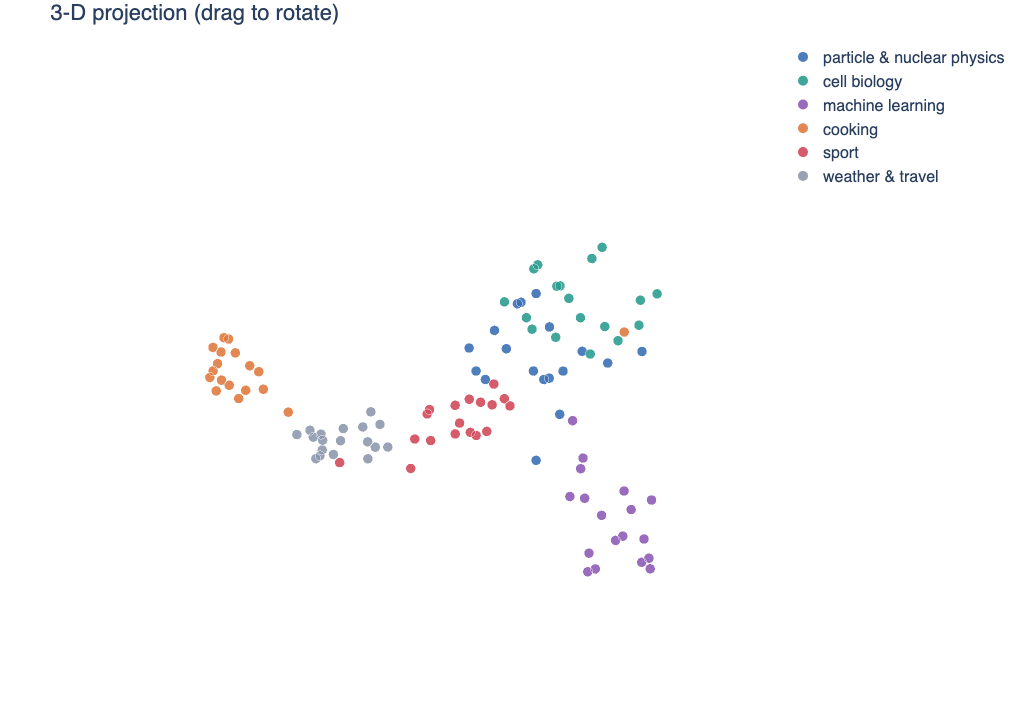

In [10]:
XYZ = umap.UMAP(n_components=3, n_neighbors=12, min_dist=0.35, metric="cosine", random_state=7).fit_transform(E)
fig = go.Figure()
for t, col in PALETTE.items():
    if t == "probes": continue
    m = labels == t
    fig.add_trace(go.Scatter3d(x=XYZ[m, 0], y=XYZ[m, 1], z=XYZ[m, 2], mode="markers", name=t,
                               marker=dict(size=5.5, color=col, opacity=0.9, line=dict(color="white", width=0.5)),
                               text=[wrap(s) for s in np.array(sentences)[m]], hovertemplate="%{text}<extra>" + t + "</extra>"))
ax = dict(visible=False)
fig.update_layout(width=1000, height=720, font=FONT, scene=dict(xaxis=ax, yaxis=ax, zaxis=ax), legend=dict(itemsizing="constant"),
                  margin=dict(l=0, r=0, t=40, b=0), title="3-D projection (drag to rotate)")
fig.show()

## Word-level panel

The same model applied to single words. Words group by kind, and some relations show up as roughly parallel directions (country to capital). Two cautions: this is a *sentence* embedder being fed one-word sentences, and the famous `king − man + woman ≈ queen` arithmetic gets its own cell right after this one.

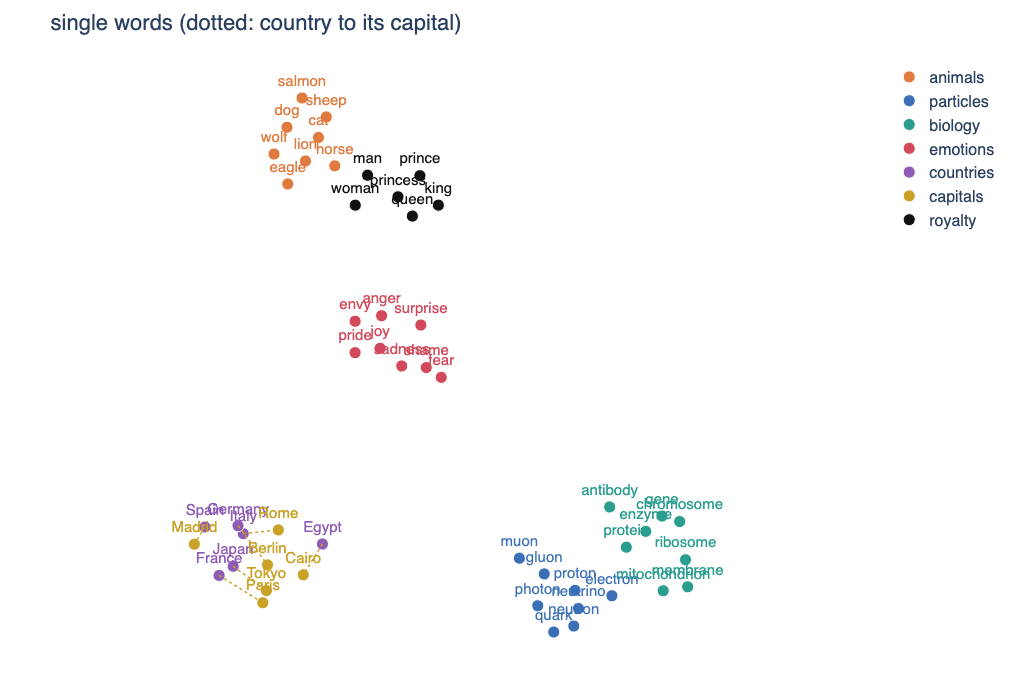

Paris - France + Japan    -> [('Tokyo', 0.77), ('Berlin', 0.48), ('photon', 0.45), ('Cairo', 0.45)]
cosine(electron, proton)  = 0.61    cosine(electron, sadness) = 0.4


In [11]:
WORDS = {
 "animals":   ["cat", "dog", "horse", "lion", "eagle", "salmon", "wolf", "sheep"],
 "particles": ["electron", "proton", "neutron", "photon", "quark", "neutrino", "muon", "gluon"],
 "biology":   ["enzyme", "protein", "gene", "chromosome", "ribosome", "antibody", "membrane", "mitochondrion"],
 "emotions":  ["joy", "anger", "fear", "sadness", "surprise", "envy", "pride", "shame"],
 "countries": ["France", "Italy", "Japan", "Egypt", "Germany", "Spain"],
 "capitals":  ["Paris", "Rome", "Tokyo", "Cairo", "Berlin", "Madrid"],
 "royalty":   ["king", "queen", "man", "woman", "prince", "princess"],
}
WCOL = {"animals": "#E07A3F", "particles": "#3B6FB6", "biology": "#2A9D8F", "emotions": "#D1495B",
        "countries": "#8E5BB5", "capitals": "#C9A227", "royalty": "#111111"}
words = [w for ws in WORDS.values() for w in ws]
wlab = np.array([g for g, ws in WORDS.items() for _ in ws])
EW = embed(words)
PW = umap.UMAP(n_neighbors=6, min_dist=0.5, metric="cosine", random_state=3).fit_transform(EW)

fig = go.Figure()
for g, col in WCOL.items():
    m = wlab == g
    fig.add_trace(go.Scatter(x=PW[m, 0], y=PW[m, 1], mode="markers+text", name=g, text=np.array(words)[m],
                             textposition="top center", textfont=dict(size=15, color=col),
                             marker=dict(size=12, color=col, line=dict(color="white", width=1))))
wi = {w: i for i, w in enumerate(words)}
for a, b in zip(WORDS["countries"], WORDS["capitals"]):
    fig.add_trace(go.Scatter(x=[PW[wi[a], 0], PW[wi[b], 0]], y=[PW[wi[a], 1], PW[wi[b], 1]], mode="lines",
                             line=dict(color="#C9A227", width=1.5, dash="dot"), hoverinfo="skip", showlegend=False))
fig.update_layout(width=1000, height=680, font=FONT, title="single words (dotted: country to its capital)",
                  xaxis=dict(visible=False), yaxis=dict(visible=False, scaleanchor="x"), margin=dict(l=10, r=10, t=60, b=10))
fig.show()

def nearest(v, exclude=(), k=4):
    s = EW @ (v / np.linalg.norm(v))
    return [(words[i], round(float(s[i]), 2)) for i in np.argsort(-s) if words[i] not in exclude][:k]
print("Paris - France + Japan    ->", nearest(EW[wi["Paris"]] - EW[wi["France"]] + EW[wi["Japan"]], exclude=("Paris", "France", "Japan")))
print("cosine(electron, proton)  =", round(float(EW[wi["electron"]] @ EW[wi["proton"]]), 2),
      "   cosine(electron, sadness) =", round(float(EW[wi["electron"]] @ EW[wi["sadness"]]), 2))

## king − man + woman, explicitly

The famous claim: take the vector for *king*, subtract *man*, add *woman*, and the nearest word is *queen*. The idea behind it is that "royal" and "gender" are **directions** in the space, so you can move along one without changing the other.

The cell does the arithmetic in the full 384 dimensions and ranks a vocabulary of about 60 words by cosine to the result. It prints the ranking twice: with the three input words allowed, and with them removed. That second step is part of every published version of this trick, and it matters: the result vector usually stays closest to *king* itself.

Two examples are drawn: **king − man + woman** (expected: queen) and **Paris − France + Japan** (expected: Tokyo). The first moves along a "gender" direction, the second along a "capital of" direction. In each picture the red arrows are the step being transferred and the blue arrows are the relation being kept.

king - man + woman
  all words allowed:    queen 0.79   king 0.75   princess 0.65   kingdom 0.65   monarch 0.64   empress 0.63
  inputs removed:       queen 0.79   princess 0.65   kingdom 0.65   monarch 0.64   empress 0.63   throne 0.61


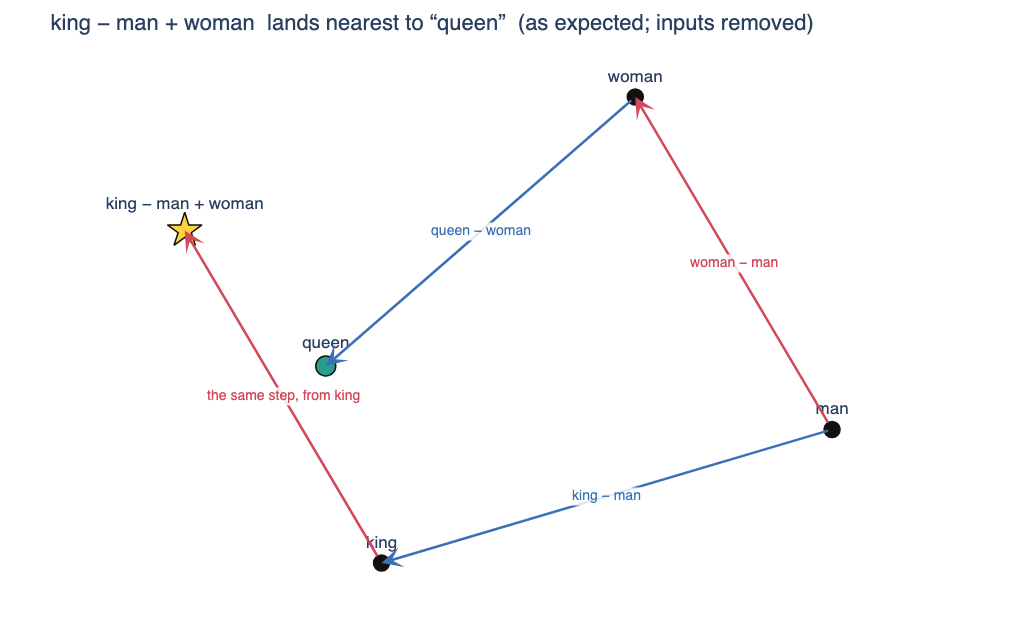

cosine(result, queen) = 0.79     cosine(result, king) = 0.75
are the two steps parallel?  cosine(woman − man, queen − king) = 0.54   (1.00 = a perfect parallelogram)

Paris - France + Japan
  all words allowed:    Tokyo 0.77   Japan 0.72   Paris 0.65   Berlin 0.48   Rome 0.40   emperor 0.35
  inputs removed:       Tokyo 0.77   Berlin 0.48   Rome 0.40   emperor 0.35   girl 0.35   people 0.34


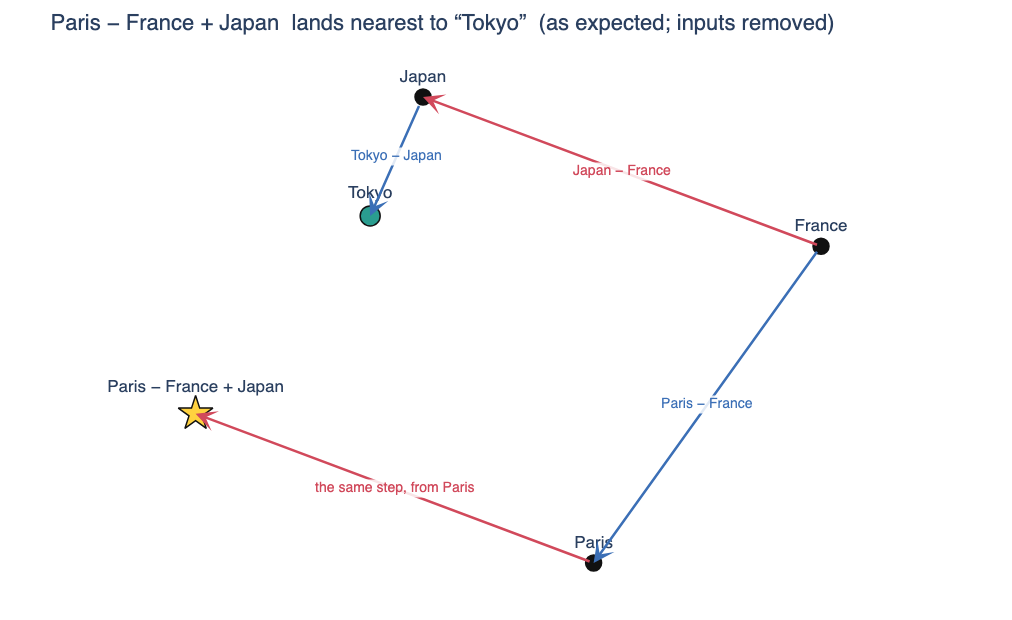

cosine(result, Tokyo) = 0.77     cosine(result, Paris) = 0.65
are the two steps parallel?  cosine(Japan − France, Tokyo − Paris) = 0.67   (1.00 = a perfect parallelogram)

two more, numbers only:
father - man + woman
  all words allowed:    father 0.75   mother 0.66   daughter 0.65   woman 0.65   wife 0.60   sister 0.54
  inputs removed:       mother 0.66   daughter 0.65   wife 0.60   sister 0.54   lady 0.53   child 0.52
actor - man + woman
  all words allowed:    actress 0.88   actor 0.74   woman 0.63   lady 0.54   queen 0.54   person 0.51
  inputs removed:       actress 0.88   lady 0.54   queen 0.54   person 0.51   child 0.49   wife 0.49


In [12]:
VOCAB = ["king", "queen", "man", "woman", "prince", "princess", "monarch", "emperor", "empress", "duke", "duchess",
         "lord", "lady", "boy", "girl", "father", "mother", "son", "daughter", "husband", "wife", "uncle", "aunt",
         "brother", "sister", "actor", "actress", "throne", "crown", "castle", "kingdom", "royal", "president",
         "teacher", "doctor", "nurse", "soldier", "farmer", "scientist", "child", "person", "people",
         "cat", "dog", "horse", "electron", "proton", "enzyme", "protein", "bread", "river", "mountain",
         "Paris", "France", "Tokyo", "Japan", "Rome", "Italy", "Berlin", "Germany"]
V = embed(VOCAB)
vi = {w: i for i, w in enumerate(VOCAB)}

def analogy(a, b, c, show=6):
    "a - b + c  ->  ?      (king - man + woman)"
    raw = V[vi[a]] - V[vi[b]] + V[vi[c]]          # the arithmetic itself
    r = raw / np.linalg.norm(raw)                 # unit length, so that V @ r is a cosine
    sims = V @ r
    order = np.argsort(-sims)
    print(f"{a} - {b} + {c}")
    print("  all words allowed:   ", "   ".join(f"{VOCAB[i]} {sims[i]:.2f}" for i in order[:show]))
    kept = [i for i in order if VOCAB[i] not in (a, b, c)]
    print("  inputs removed:      ", "   ".join(f"{VOCAB[i]} {sims[i]:.2f}" for i in kept[:show]))
    return raw, r, VOCAB[kept[0]]

def draw(a, b, c, expected):
    "Picture of  a - b + c  against the expected word.  Every arrow runs from its tail word to its head word."
    raw, r, answer = analogy(a, b, c)
    # PCA on just these five points: the flat view that spreads them out most. PCA is linear, so the two
    # red arrows are exactly equal and parallel on screen: the star is the fourth corner of the
    # parallelogram built on b, c and a. Its distance from the expected word is the error.
    star = f"{a} − {b} + {c}"
    pts = [b, c, a, expected]
    P2 = PCA(n_components=2).fit_transform(np.vstack([V[[vi[w] for w in pts]], raw]))
    pos = {w: P2[i] for i, w in enumerate(pts)}; pos[star] = P2[-1]
    fig = go.Figure()
    def arrow(t, h, color, text):
        fig.add_annotation(x=pos[h][0], y=pos[h][1], ax=pos[t][0], ay=pos[t][1], xref="x", yref="y", axref="x", ayref="y",
                           showarrow=True, arrowhead=3, arrowsize=1.4, arrowwidth=2.5, arrowcolor=color)
        fig.add_annotation(x=(pos[t][0] + pos[h][0]) / 2, y=(pos[t][1] + pos[h][1]) / 2, text=text, showarrow=False,
                           font=dict(size=14, color=color), bgcolor="rgba(255,255,255,0.85)")
    arrow(b, c, "#D1495B", f"{c} − {b}")
    arrow(a, star, "#D1495B", f"the same step, from {a}")
    arrow(b, a, "#3B6FB6", f"{a} − {b}")
    arrow(c, expected, "#3B6FB6", f"{expected} − {c}")
    for w, col, sym, size in [(b, "#111111", "circle", 16), (c, "#111111", "circle", 16), (a, "#111111", "circle", 16),
                              (expected, "#2A9D8F", "circle", 20), (star, "#FFD23F", "star", 26)]:
        fig.add_trace(go.Scatter(x=[pos[w][0]], y=[pos[w][1]], mode="markers+text", text=[w], textposition="top center",
                                 textfont=dict(size=17), marker=dict(size=size, color=col, symbol=sym, line=dict(color="#111111", width=1.5)),
                                 showlegend=False, hoverinfo="skip"))
    verdict = "as expected" if answer == expected else f"expected “{expected}”"
    fig.update_layout(width=900, height=620, font=FONT, title=f"{star}  lands nearest to “{answer}”  ({verdict}; inputs removed)",
                      xaxis=dict(visible=False), yaxis=dict(visible=False, scaleanchor="x"), margin=dict(l=20, r=20, t=60, b=20))
    fig.show()
    d1 = V[vi[c]] - V[vi[b]]; d2 = V[vi[expected]] - V[vi[a]]
    print(f"cosine(result, {expected}) = {float(r @ V[vi[expected]]):.2f}     cosine(result, {a}) = {float(r @ V[vi[a]]):.2f}")
    print(f"are the two steps parallel?  cosine({c} − {b}, {expected} − {a}) = {float(d1 @ d2 / np.linalg.norm(d1) / np.linalg.norm(d2)):.2f}   (1.00 = a perfect parallelogram)")
    print()

draw("king", "man", "woman", "queen")       # the gender direction
draw("Paris", "France", "Japan", "Tokyo")   # the capital-of direction

print("two more, numbers only:")
analogy("father", "man", "woman")
analogy("actor", "man", "woman");

**Reading it.** The two red arrows are equal and parallel by construction: the star is where the step lands when you take it from the third word. The question is how close the star is to the green dot. When it is close, the relation ("gender", "capital of") is roughly the same direction wherever you start. Compare the two pictures: which relation is the cleaner direction in this model? Three honest notes:

- The star is usually still closer to the word you started from (*king*, *Paris*) than to the expected answer. The trick works only after the input words are removed from the candidates.
- The last printed number says how parallel the two steps really are. Expect it to be well below 1.
- This model was trained on sentences, and each word here is a one-word sentence. The original result (Mikolov and colleagues, 2013) used word vectors trained for exactly this. Each picture is a 2-D view chosen to contain its five points; the arithmetic was done in all 384 dimensions.

## What to take from this

1. An embedding is a list of numbers; **meaning is position**, and similarity is the cosine between two positions.
2. The model was never told the topics. It recovered them from text alone.
3. Vectors capture **paraphrase and topic**. They are nearly blind to **negation, exact numbers and direction of effect**. That is a property, and the reason hybrid search adds a keyword index.
4. Search is "embed the query with the same model, take the nearest rows". You just did it by hand.
5. A 2-D map is a picture of neighbourhoods. Distances on it are not measurements.

**Try:** add a seventh topic from your own field to `TOPICS` and rerun. Where does it land? Which existing topic does it touch?